# 01 - Exploratory data analysis (EMBER2024, Win64)

This notebook is a narrative view only. Every number comes from `src.data` and from the files that
`run_all.py --steps data` wrote. No logic lives here.

**We only look at the `train` split.** `test_random` and `test_future` stay unseen until final
scoring, so nothing we notice here can steer modelling choices.

**How the splits were made** (the code is in `src/data.py` and `scripts/build_cache.py`): the raw
weekly files list each sample twice, so rows are de-duplicated by sha256 first. `train` and
`test_random` are a stratified (label x week) random split of weeks 0-51; `test_future` is drawn
from weeks 52-63, which all come after every training week.

In [1]:
# Make the project root importable when the notebook is opened from notebooks/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config
from src.data import feature_groups, load_split

X, y, meta = load_split("train")
print(f"train: X {X.shape} {X.dtype}, quick={config.QUICK}")

train: X (160000, 2568) float32, quick=False


## Data checks from `verify_data.py`

`scripts/verify_data.py` writes every count and flag to `reports/data_check.json`. The flags are
shown here so nobody has to open the file. Expect a flag about `detection_ratio`, which is almost a
copy of the label.

In [3]:
check_path = config.REPORTS / f"data_check{config.RUN_SUFFIX}.json"
report = json.loads(check_path.read_text(encoding="utf-8"))
print("hard checks:", report.get("hard_checks"))
for flag in report.get("flags", []):
    print("FLAG:", flag)

hard checks: {'groups_sum_to_dim': True, 'rows_match_meta': True, 'labels_only_0_1': True, 'no_line_count_mismatch': True, 'no_sha256_overlap_across_splits': True, 'no_duplicate_sha256_within_splits': True, 'test_future_strictly_later': True, 'tune_subset_valid': True, 'cv_folds_partition_ok': True, 'alignment_ok': True}
FLAG: train: 520000 of 1040000 raw lines were in-file duplicate sha256 (each weekly file repeats its 10k samples); dropped, first occurrence kept.
FLAG: test: 120000 of 240000 raw lines were in-file duplicate sha256 (each weekly file repeats its 10k samples); dropped, first occurrence kept.
FLAG: test: 7 sha256 appeared in two different weeks; only the earliest week's row is kept.
FLAG: train: detection_ratio_float alone gives ROC-AUC 1.0000 - a near-perfect label proxy. Expected (labels are derived from AV detections); it is kept only in meta, never in X.
FLAG: test: detection_ratio_float alone gives ROC-AUC 1.0000 - a near-perfect label proxy. Expected (labels are de

## Class balance

EMBER2024 is exactly 50/50 benign/malicious every week **by construction**. Real traffic is mostly
benign, so precision measured here is optimistic. Notebook 04 shows how much precision drops at a
realistic 1% malware prevalence.

In [4]:
meta["label"].map({0: "benign", 1: "malicious"}).value_counts().to_frame("count")

,count
label,
benign,80003
malicious,79997


## Samples per week

`train` is a stratified (label x week) sample of the 52 training weeks, so each week should keep its
share and its 50/50 balance.

label,benign,malicious
count,52.000000,52.000000
mean,1538.519231,1538.403846
std,0.504505,0.495454
min,1538.000000,1538.000000
25%,1538.000000,1538.000000
50%,1539.000000,1538.000000
75%,1539.000000,1539.000000
max,1539.000000,1539.000000


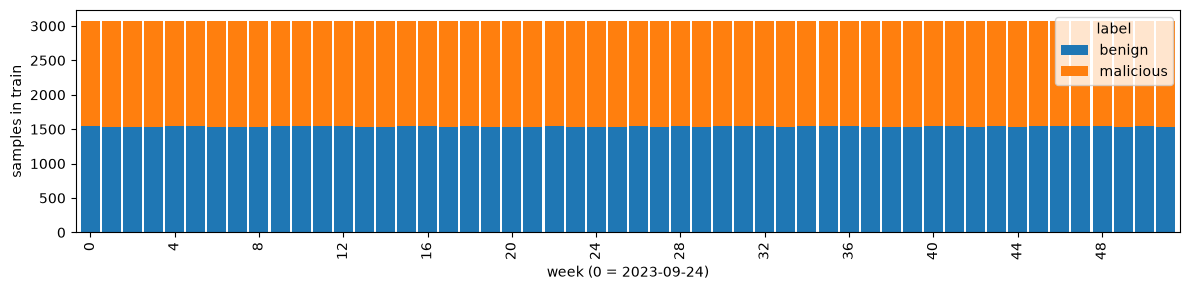

In [5]:
per_week = meta.groupby(["week", "label"]).size().unstack("label").rename(columns={0: "benign", 1: "malicious"})
ax = per_week.plot(kind="bar", stacked=True, figsize=(12, 3), width=0.9)
ax.set_xlabel("week (0 = 2023-09-24)")
ax.set_ylabel("samples in train")
ax.set_xticks(ax.get_xticks()[::4])
plt.tight_layout()
per_week.describe()

## Feature families

The 2,568 columns come in 12 families. The column ranges come from `feature_groups()`, which reads
them from the thrember extractor. Below, each sample's mean value inside a few families is compared
between benign and malicious files. This is a rough look at whether a family separates the classes.

In [6]:
groups = pd.DataFrame(feature_groups(), columns=["family", "start", "end"])
groups["width"] = groups["end"] - groups["start"]
groups

C:\projects\automl\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,family,start,end,width
0,general,0,7,7
1,histogram,7,263,256
2,byteentropy,263,519,256
3,strings,519,696,177
4,header,696,770,74
5,section,770,994,224
6,imports,994,2276,1282
7,exports,2276,2405,129
8,datadirectories,2405,2439,34
9,richheader,2439,2472,33


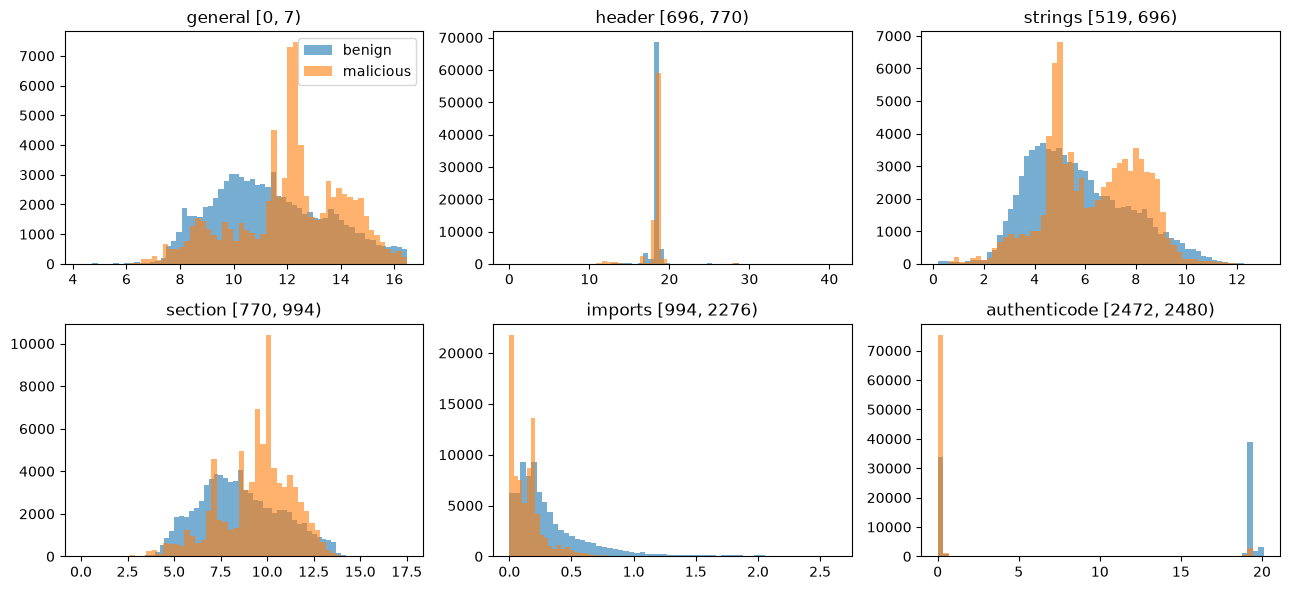

In [7]:
# byteentropy and histogram are left out: each file's values there are normalised to sum to 1,
# so their per-file mean is the same constant for every file and shows nothing.
families = ["general", "header", "strings", "section", "imports", "authenticode"]
ranges = groups.set_index("family").loc[families, ["start", "end"]]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (name, start, end) in zip(axes.flat, ranges.itertuples()):
    # log1p of the per-sample mean, because several families span many orders of magnitude
    family_mean = np.log1p(np.abs(X[:, start:end]).mean(axis=1))
    for label, colour in ((0, "tab:blue"), (1, "tab:orange")):
        ax.hist(family_mean[y == label], bins=60, alpha=0.6, color=colour,
                label="benign" if label == 0 else "malicious")
    ax.set_title(f"{name} [{start}, {end})")
axes.flat[0].legend()
plt.tight_layout()

## A time proxy inside the standard features

Column 696 is `header.coff.timestamp`, the PE compile time. It is part of the normal 2,568-dim
vector, so models can learn *when* a file was built. That helps more on a random split (train and
test come from the same months) than on future weeks. The authenticode signing-time columns are a
second time proxy of the same kind. Notebook 04 checks how high these columns rank.

In [8]:
compile_time = pd.to_datetime(X[:, 696].astype("int64"), unit="s", errors="coerce")
pd.DataFrame({"label": y, "compile_year": compile_time.year}).groupby("label")["compile_year"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,80003.0,2021.733847,19.143105,1970.0,2022.0,2023.0,2024.0,2106.0
1,79997.0,2015.907022,20.950810,1970.0,2019.0,2023.0,2024.0,2106.0


## `detection_ratio` vs label: the leaky feature

`detection_ratio` is the share of antivirus engines that flag the file. The label is derived from
those same verdicts, so this column is an almost perfect label proxy. It is **never** part of `X` in
the main runs. Step 4 adds it on purpose to see which tools notice the leak.

In [9]:
positives = meta["detection_ratio"].str.split("/").str[0].astype(int)
bins = pd.cut(positives, bins=[-1, 0, 4, 10, 30, 100], labels=["0", "1-4", "5-10", "11-30", ">30"])
pd.crosstab(meta["label"].map({0: "benign", 1: "malicious"}), bins)

detection_ratio,0,1-4,5-10,11-30,>30
label,,,,,
benign,79969,34,0,0,0
malicious,0,0,12404,19650,47943


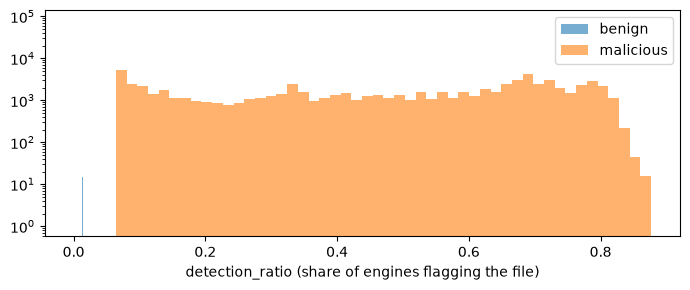

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
for label, colour in ((0, "tab:blue"), (1, "tab:orange")):
    ax.hist(meta.loc[meta["label"] == label, "detection_ratio_float"], bins=50, alpha=0.6, color=colour,
            label="benign" if label == 0 else "malicious")
ax.set_xlabel("detection_ratio (share of engines flagging the file)")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()

## What we take forward

* Classes are balanced by construction, so accuracy and F1 look better than they would on real
  traffic. We also report TPR at 1% FPR, which does not depend on the class mix.
* Weeks are equally represented, so `test_random` mixes all 52 training weeks. Only `test_future`
  measures performance on later malware.
* `detection_ratio` and `first_submission_date` stay out of `X`. Step 4 adds them on purpose
  (notebook 04).
* The compile and signing time columns are inside `X` and are allowed, but they may help a random
  split more than a future one. Step 4 tests this with SHAP and an ablation.